# 01 - Data loading and cleaning

**Project question:** do the 5 traditional positions (PG, SG, SF, PF, C) describe how NBA players actually play?

**Goal of this notebook:** load the raw Basketball-Reference table (2025-26 season, *per 36 minutes*), inspect it, fix its problems and save a clean version for the next notebook.

**Input:** `data/raw/bbref_per36_2025_26.csv`
**Output:** `data/processed/players_per36_clean.csv`

## 1. Imports and paths

`pandas` is the library for tables (called *DataFrames*). `Path` builds file paths in a way that works on any operating system.

In [1]:
from pathlib import Path

import pandas as pd

RAW_PATH = Path("../data/raw/bbref_per36_2025_26.csv")
PROCESSED_PATH = Path("../data/processed/players_per36_clean.csv")

## 2. Load the raw data

`pd.read_csv` reads the file into a DataFrame. We always look at it before touching it.

In [5]:
df_raw = pd.read_csv(RAW_PATH)
df_raw.shape  # (rows, columns)

(582, 32)

In [6]:
df_raw.head()

,Rk,Player,Age,Team,Pos,G,GS,MP▼,FG,FGA,...,DRB,TRB,AST,STL,BLK,TOV,PF,PTS,Awards,Player-additional
0,1,Amen Thompson,23,HOU,PG,79,79,2953,6.8,12.7,...,4.6,7.5,5.1,1.5,0.6,2.3,2.1,17.6,DPOY-8,thompam01
1,2,Kevin Durant,37,HOU,SF,78,78,2840,9.1,17.4,...,4.9,5.4,4.7,0.8,0.9,3.1,1.8,25.7,CPOY-9ASNBA2,duranke01
2,3,Desmond Bane,27,ORL,SG,82,82,2756,7.6,15.7,...,3.1,4.4,4.4,1.1,0.5,2.1,3.3,21.5,NaN,banede01
3,4,Toumani Camara,25,POR,PF,82,82,2731,5.2,11.7,...,3.8,5.5,2.6,1.2,0.5,1.9,3.1,14.5,NaN,camarto01
4,5,Jabari Smith Jr.,22,HOU,PF,77,77,2705,5.8,13.0,...,5.6,7.0,1.9,0.7,0.9,1.4,2.6,16.2,NaN,smithja05


`info()` shows each column's type and how many values are *not* missing. Look for columns where that count is lower than the number of rows.

In [7]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 582 entries, 0 to 581
Data columns (total 32 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Rk                 582 non-null    int64  
 1   Player             582 non-null    str    
 2   Age                582 non-null    int64  
 3   Team               582 non-null    str    
 4   Pos                582 non-null    str    
 5   G                  582 non-null    int64  
 6   GS                 582 non-null    int64  
 7   MP▼                582 non-null    int64  
 8   FG                 582 non-null    float64
 9   FGA                582 non-null    float64
 10  FG%                582 non-null    float64
 11  3P                 582 non-null    float64
 12  3PA                582 non-null    float64
 13  3P%                547 non-null    float64
 14  2P                 582 non-null    float64
 15  2PA                582 non-null    float64
 16  2P%                579 non-null    fl

## 3. Problems found in the raw data

Let's check them one by one instead of assuming.

**Problem A - a column name has a stray symbol.** The minutes column is called `MP▼` (the arrow comes from the sort indicator on the website).

In [8]:
[col for col in df_raw.columns if not col.isascii()]

['MP▼']

**Problem B - possible repeated players.** A player traded during the season could appear several times (one row per team plus a combined row). The `Player-additional` column is a unique player id, so it is safer than the name.

In [14]:
df_raw["Player-additional"].duplicated().sum()

np.int64(0)

Zero repeats: this table already has **one row per player**. Players who changed team show a combined team label like `2TM` or `3TM` instead of a team code.

In [15]:
multi_team = df_raw["Team"].str.fullmatch(r"\d+TM")
df_raw.loc[multi_team, ["Player", "Team", "Pos", "G", "MP▼"]].head()

,Player,Team,Pos,G,MP▼
22,James Harden,2TM,PG,70,2438
43,CJ McCollum,2TM,PG,76,2264
99,Ayo Dosunmu,2TM,SG,69,1881
110,Nikola Vučević,2TM,C,64,1818
133,Dennis Schröder,2TM,PG,70,1697


**Problem C - a summary row at the bottom.** Other exports of this site end with a `League Average` row that is not a player. Let's confirm it is not here.

In [16]:
(df_raw["Player"] == "League Average").any()

np.False_

**Problem D - missing values.** Which columns have them, and why?

In [17]:
missing = df_raw.isna().sum()
missing[missing > 0]

3P%        35
2P%         3
FT%        19
Awards    528
dtype: int64

The percentage columns (`3P%`, `FT%`, `2P%`) are empty when a player attempted **zero** shots of that type: a percentage of 0 divided by 0 does not exist. Let's verify that explanation instead of trusting it.

In [18]:
df_raw.loc[df_raw["3P%"].isna(), ["Player", "3PA"]].head()

,Player,3PA
83,Jalen Duren,0.0
86,Deandre Ayton,0.0
177,Ivica Zubac,0.0
182,Luke Kornet,0.0
210,Jericho Sims,0.0


All of them have `3PA = 0.0`, so the explanation holds. We will **not** fill these values yet: how to treat them depends on which features we choose, and that is the next notebook.

`Awards` is also mostly empty, but it is irrelevant for our question, so we simply drop it.

## 4. Clean

Plan:
1. Rename columns to short English `snake_case` names. Counting stats get a `_per36` suffix so we never forget their unit.
2. Drop columns we will not use (`Rk` is just a ranking, `Awards` is irrelevant).
3. Check the result.

In [19]:
COLUMN_NAMES = {
    "Player-additional": "player_id",
    "Player": "player",
    "Age": "age",
    "Team": "team",
    "Pos": "position",
    "G": "games",
    "GS": "games_started",
    "MP▼": "minutes_total",
    "FG": "fg_per36",
    "FGA": "fga_per36",
    "FG%": "fg_pct",
    "3P": "fg3_per36",
    "3PA": "fg3a_per36",
    "3P%": "fg3_pct",
    "2P": "fg2_per36",
    "2PA": "fg2a_per36",
    "2P%": "fg2_pct",
    "eFG%": "efg_pct",
    "FT": "ft_per36",
    "FTA": "fta_per36",
    "FT%": "ft_pct",
    "ORB": "orb_per36",
    "DRB": "drb_per36",
    "TRB": "trb_per36",
    "AST": "ast_per36",
    "STL": "stl_per36",
    "BLK": "blk_per36",
    "TOV": "tov_per36",
    "PF": "pf_per36",
    "PTS": "pts_per36",
}

In [20]:
df = df_raw[list(COLUMN_NAMES)].rename(columns=COLUMN_NAMES)
df.columns.tolist()

['player_id',
 'player',
 'age',
 'team',
 'position',
 'games',
 'games_started',
 'minutes_total',
 'fg_per36',
 'fga_per36',
 'fg_pct',
 'fg3_per36',
 'fg3a_per36',
 'fg3_pct',
 'fg2_per36',
 'fg2a_per36',
 'fg2_pct',
 'efg_pct',
 'ft_per36',
 'fta_per36',
 'ft_pct',
 'orb_per36',
 'drb_per36',
 'trb_per36',
 'ast_per36',
 'stl_per36',
 'blk_per36',
 'tov_per36',
 'pf_per36',
 'pts_per36']

Selecting `df_raw[list_of_columns]` keeps only those columns (so `Rk` and `Awards` are gone), and `.rename(columns=...)` changes their names.

## 5. Sanity checks

Cleaning can silently break things, so we verify. One row per player, no missing positions, and a known player looks right.

In [21]:
assert df["player_id"].is_unique
assert df["position"].notna().all()
df.shape

(582, 30)

In [22]:
df["position"].value_counts()

position
SG    161
SF    111
C     107
PF    106
PG     97
Name: count, dtype: int64

In [23]:
df[df["player"].isin(["Nikola Jokić", "Luka Dončić"])][["player", "position", "games", "minutes_total", "pts_per36", "trb_per36", "ast_per36"]]

,player,position,games,minutes_total,pts_per36,trb_per36,ast_per36
36,Luka Dončić,PG,64,2289,33.7,7.8,8.3
42,Nikola Jokić,C,65,2265,28.6,13.3,11.1


## 6. A look at playing time

Per-36 numbers are only reliable if a player has played enough minutes. Here is the distribution of total minutes over the season; the very long tail of players near zero is what we will have to filter in the next notebook.

In [24]:
df["minutes_total"].describe()

count     582.000000
mean     1019.786942
std       771.979401
min         3.000000
25%       293.250000
50%       940.500000
75%      1610.000000
max      2953.000000
Name: minutes_total, dtype: float64

Text(0.5, 0, 'Total minutes')

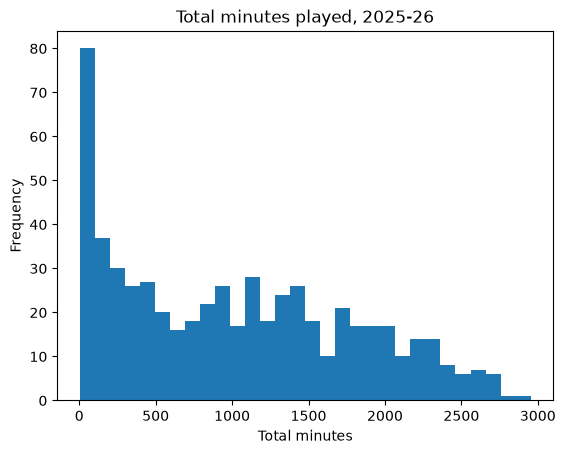

In [25]:
ax = df["minutes_total"].plot.hist(bins=30, title="Total minutes played, 2025-26")
ax.set_xlabel("Total minutes")

## 7. Save

We save the clean table so the next notebook can start from it. `index=False` avoids writing the row numbers as an extra column.

In [26]:
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False)
PROCESSED_PATH

PosixPath('../data/processed/players_per36_clean.csv')

## Summary

- 582 players, one row each, with their official position (5 classes).
- Columns renamed to English `snake_case`; counting stats carry a `_per36` suffix.
- Missing percentages are left as-is on purpose and handled in notebook 02.
- Next: filter players with too few minutes and choose the features for clustering.